## Evaluation of Attention vs. Non-Attention Models on German-English dataset

Based on the two sample reports provided earlier, use the new bilingual dataset to carry out the following tasks:

1. **Model without Attention**
   - Implement a baseline sequence-to-sequence model (encoder + decoder) without any attention mechanism.
   - Train the model on the dataset and record the performance.
   - Report both token-level accuracy and BLEU score.

2. **Model with Attention**
   - Implement a sequence-to-sequence model with an attention mechanism.
   - Train the model on the same dataset under comparable conditions.
   - Report both token-level accuracy and BLEU score.

3. **Comparison and Analysis**
   - Present the results of both models in a comparative table (accuracy and BLEU).
   - Provide a short discussion analyzing:
     - How attention influences translation quality.
     - Strengths and weaknesses of each approach.
     - Which type of sentences (short vs. long, simple vs. complex) benefit most from attention.

4. **Deliverables (optional)**
   - A Markdown or PDF report containing:
     - Model descriptions
     - Training setup (hyperparameters, epochs, etc.)
     - Quantitative results
     - Comparative discussion
   - Optionally, include a few qualitative translation examples showing differences between the two models.


# Setup Environment

In [1]:
from __future__ import unicode_literals, print_function, division

import re
import math
import random
import string
import unicodedata
from io import open

import numpy as np

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import seaborn as sns

In [2]:
seed = 123
np.random.seed(seed)
_ = torch.manual_seed(seed)
_ = torch.cuda.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
def plot_attention(attention, xtitle="Keys", ytitle="Queries"):
    """ Plots the attention map."""

    sns.set(rc={'figure.figsize':(12, 8)})
    ax = sns.heatmap(
        attention.detach().cpu(),
        linewidth=0.5,
        cmap="Blues",
        square=True)

    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xlabel(xtitle)
    ax.set_ylabel(ytitle)

    plt.show()

In [4]:
!gdown 1CVMenH5xgDsiq9ZaGAFfkFLG5uWDZvdL
!mkdir data
!mv "german-english.txt" "data/eng-ger.txt"

Downloading...
From: https://drive.google.com/uc?id=1CVMenH5xgDsiq9ZaGAFfkFLG5uWDZvdL
To: /content/german-english.txt
100% 10.8M/10.8M [00:00<00:00, 19.3MB/s]


In [5]:
SOS_token = 0
EOS_token = 1

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2  # Count SOS and EOS

    def addSentence(self, sentence):
        for word in sentence.split(' '):
            self.addWord(word)

    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

In [6]:
# Turn a Unicode string to plain ASCII, thanks to
# http://stackoverflow.com/a/518232/2809427
import unicodedata
import re
import random

# Turn a Unicode string to plain ASCII
def unicodeToAscii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalizeString(s):
    s = unicodeToAscii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z.!?]+", r" ", s)
    return s


def readLangs(lang1, lang2, reverse=False):
    print("Reading lines...")

    lines = open(f'data/{lang1}-{lang2}.txt', encoding='utf-8').read().strip().split('\n')

    # Remove extra info (like "CC-BY" tag)
    new_lines = []
    for line in lines:
        cut = line.find('CC-BY')
        if cut != -1:
            line = line[:cut].strip()
        new_lines.append(line)

    # Split and normalize
    pairs = [[normalizeString(s) for s in l.split('\t')] for l in new_lines if '\t' in l]

    # Reverse if needed
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)

    return input_lang, output_lang, pairs


MAX_LENGTH = 20

def filterPair(p):
    return len(p[0].split(' ')) < MAX_LENGTH and len(p[1].split(' ')) < MAX_LENGTH

def filterPairs(pairs):
    return [pair for pair in pairs if filterPair(pair)]

#Split train - testset at fix random seed for fair comparision
def prepareData(lang1, lang2, reverse=False, test_size=10000, seed=42):
    input_lang, output_lang, pairs = readLangs(lang1, lang2, reverse)
    print(f"Read {len(pairs)} sentence pairs")

    pairs = filterPairs(pairs)
    print(f"Trimmed to {len(pairs)} sentence pairs")

    # Shuffle with a fixed random seed for reproducibility
    random.seed(seed)
    random.shuffle(pairs)

    # Split train/test
    if len(pairs) <= test_size:
        raise ValueError("Not enough sentence pairs to take 1000 as test set.")

    test_pairs = pairs[:test_size]
    train_pairs = pairs[test_size:]

    print(f"Training pairs: {len(train_pairs)}")
    print(f"Test pairs: {len(test_pairs)}")

    # Build vocab from training set only (important to avoid data leakage)
    print("Counting words from training set...")
    for pair in train_pairs:
        input_lang.addSentence(pair[0])
        output_lang.addSentence(pair[1])

    print("Counted words:")
    print(input_lang.name, input_lang.n_words)
    print(output_lang.name, output_lang.n_words)

    return input_lang, output_lang, train_pairs, test_pairs


# Example usage
input_lang, output_lang, train_pairs, test_pairs = prepareData('eng', 'ger', False)
print(random.choice(train_pairs))

Reading lines...
Read 152820 sentence pairs
Trimmed to 152371 sentence pairs
Training pairs: 142371
Test pairs: 10000
Counting words from training set...
Counted words:
eng 14402
ger 29649
['i had heard that he was fat but i didnt think he would be that fat', 'ich hatte gehort dass er dick war aber ich hatte nicht gedacht dass er in dem mae dick ware']


In [7]:
class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1, max_length=MAX_LENGTH):
        super(DecoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.dropout_p = dropout_p
        self.max_length = max_length

        self.embedding = nn.Embedding(self.output_size, self.hidden_size)
        self.gru = nn.GRU(self.hidden_size, self.hidden_size, batch_first=True)
        self.dropout = nn.Dropout(self.dropout_p)
        # Removed attention mechanism
        # self.attn = AdditiveAttention(self.hidden_size, self.hidden_size, self.hidden_size // 2)
        # self.attn_combine = nn.Linear(self.hidden_size * 2, self.hidden_size)
        self.out = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, input, hidden, encoder_outputs):
        embedded = self.embedding(input)
        embedded = self.dropout(embedded)

        # Only use the hidden state from the GRU for the output
        output, hidden = self.gru(embedded, hidden)

        # Removed attention computation and combination
        # context, attn_weights = self.attn(query=x, key=encoder_outputs, value=encoder_outputs)
        # x_w_context = torch.cat((x, context), dim=-1)
        # x_w_context = self.attn_combine(x_w_context)

        output = F.log_softmax(self.out(output), dim=-1)
        # Return None for attention weights as they are no longer computed
        return output, hidden, None

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

In [8]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size

        # TODO: Define the Embedding matrix (use nn.Embedding)
        self.embedding = nn.Embedding(input_size, hidden_size)

        self.gru = nn.GRU(hidden_size, hidden_size, batch_first=True)

    def forward(self, input, hidden):
        embedded = self.embedding(input)
        output = embedded
        output, hidden = self.gru(output, hidden)
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

In [9]:
def indexesFromSentence(lang, sentence):
    return [lang.word2index[word] for word in sentence.split(' ')]


def tensorFromSentence(lang, sentence):
    indexes = indexesFromSentence(lang, sentence)
    indexes.append(EOS_token)
    return torch.tensor(indexes, dtype=torch.long, device=device).view(1, -1)


def tensorsFromPair(pair):
    input_tensor = tensorFromSentence(input_lang, pair[0])
    target_tensor = tensorFromSentence(output_lang, pair[1])
    return (input_tensor, target_tensor)

In [10]:
def train(input_tensor, target_tensor, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion, max_length=MAX_LENGTH):
    encoder_hidden = encoder.initHidden()

    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()

    encoder_outputs, encoder_hidden = encoder(input_tensor, encoder_hidden)

    # First hidden state used by the decoder is the last encoder hidden state
    decoder_hidden = encoder_hidden

    # We feed the decoder with the whole target sentence (teacher forcing),
    # first we append SOS_token
    decoder_input = torch.cat([
        torch.tensor([[SOS_token]], device=device),
        target_tensor[:, :-1]
    ], dim=1)


    # Modified to not receive attention weights
    decoder_output, decoder_hidden, _ = decoder(
                decoder_input, decoder_hidden, encoder_outputs)

    loss = criterion(
        decoder_output.view(-1, decoder_output.size(-1)),
        target_tensor.view(-1)
    )
    loss.backward()

    encoder_optimizer.step()
    decoder_optimizer.step()

    return loss.item() / target_tensor.numel()

In [11]:
import time

def asMinutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)


def timeSince(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (asMinutes(s), asMinutes(rs))

def showPlot(points):
    plt.figure()
    fig, ax = plt.subplots()
    # this locator puts ticks at regular intervals
    loc = ticker.MultipleLocator(base=0.2)
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)

In [12]:
def trainIters(encoder, decoder, n_iters, print_every=1000, plot_every=100, learning_rate=0.003):
    start = time.time()
    plot_losses = []
    print_loss_total = 0  # Reset every print_every
    plot_loss_total = 0  # Reset every plot_every

    encoder_optimizer = optim.SGD(encoder.parameters(), lr=learning_rate)
    decoder_optimizer = optim.SGD(decoder.parameters(), lr=learning_rate)

    # Random sample of n_iters pairs
    training_pairs = [tensorsFromPair(random.choice(train_pairs))
                      for i in range(n_iters)]
    criterion = nn.NLLLoss()

    for iter in range(1, n_iters + 1):
        training_pair = training_pairs[iter - 1]
        input_tensor = training_pair[0]
        target_tensor = training_pair[1]

        loss = train(input_tensor, target_tensor, encoder,
                     decoder, encoder_optimizer, decoder_optimizer, criterion)
        print_loss_total += loss
        plot_loss_total += loss

        if iter % print_every == 0:
            print_loss_avg = print_loss_total / print_every
            print_loss_total = 0
            print('%s (%d %d%%) %.4f' % (timeSince(start, iter / n_iters),
                                         iter, iter / n_iters * 100, print_loss_avg))

        if iter % plot_every == 0:
            plot_loss_avg = plot_loss_total / plot_every
            plot_losses.append(plot_loss_avg)
            plot_loss_total = 0

    showPlot(plot_losses)

0m 23s (- 6m 11s) (3000 6%) 1.3220
0m 36s (- 4m 27s) (6000 12%) 1.0264
0m 49s (- 3m 44s) (9000 18%) 0.9584
1m 2s (- 3m 16s) (12000 24%) 0.9356
1m 14s (- 2m 54s) (15000 30%) 0.9169
1m 27s (- 2m 35s) (18000 36%) 0.8802
1m 41s (- 2m 19s) (21000 42%) 0.8957
1m 53s (- 2m 3s) (24000 48%) 0.8891
2m 6s (- 1m 48s) (27000 54%) 0.8693
2m 19s (- 1m 33s) (30000 60%) 0.8656
2m 32s (- 1m 18s) (33000 66%) 0.8604
2m 45s (- 1m 4s) (36000 72%) 0.8544
2m 58s (- 0m 50s) (39000 78%) 0.8406
3m 11s (- 0m 36s) (42000 84%) 0.8420
3m 24s (- 0m 22s) (45000 90%) 0.8440
3m 36s (- 0m 9s) (48000 96%) 0.8332


<Figure size 640x480 with 0 Axes>

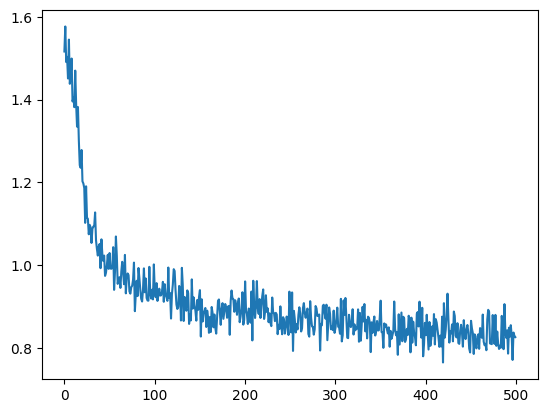

In [13]:
hidden_size = 256
encoder1 = EncoderRNN(input_lang.n_words, hidden_size).to(device)
attn_decoder1 = DecoderRNN(hidden_size, output_lang.n_words, dropout_p=0.1).to(device)

trainIters(encoder1, attn_decoder1, 50000, print_every=3000)

In [14]:
def evaluate(encoder, decoder, sentence, max_length=MAX_LENGTH):
    with torch.no_grad():
        input_tensor = tensorFromSentence(input_lang, sentence)
        encoder_hidden = encoder.initHidden()

        encoder_outputs, encoder_hidden = encoder(input_tensor, encoder_hidden)

        decoder_input = torch.tensor([[SOS_token]], device=device)  # (1,1)
        decoder_hidden = encoder_hidden

        decoded_words = []

        for _ in range(max_length):
            # Cho phép decoder trả (out, hid) hoặc (out, hid, attn)
            ret = decoder(decoder_input, decoder_hidden, encoder_outputs)
            if isinstance(ret, (tuple, list)):
                if len(ret) == 3:
                    decoder_output, decoder_hidden, _ = ret  # bỏ qua attention
                elif len(ret) == 2:
                    decoder_output, decoder_hidden = ret
                else:
                    raise ValueError(f"Decoder returned {len(ret)} values, expected 2 or 3.")
            else:
                raise ValueError("Decoder must return (output, hidden) or (output, hidden, attn).")

            # decoder_output shape: (1, 1, vocab_size)
            topv, topi = decoder_output.data.topk(1)     # topi: (1,1,1)

            # Lấy id để kiểm tra EOS
            idx = topi.squeeze().item()                  # scalar
            if idx == EOS_token:
                decoded_words.append('<EOS>')
                break
            decoded_words.append(output_lang.index2word[idx])

            # Làm input cho bước sau, giữ shape (1,1)
            decoder_input = topi.squeeze(-1).detach()    # (1,1)

        return decoded_words, None

In [15]:
def sentence_accuracy(pred_tokens, ref_tokens):
    # cắt theo độ dài nhỏ hơn
    print('pred_tokens', pred_tokens)
    print('ref_tokens', ref_tokens)
    min_len = min(len(pred_tokens), len(ref_tokens))
    correct = sum(1 for i in range(min_len) if pred_tokens[i] == ref_tokens[i])
    return correct / max(len(ref_tokens), 1)

In [16]:
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

def evaluateRandomly(encoder, decoder, n=10):
    smoothie = SmoothingFunction().method4
    for i in range(n):
        pair = random.choice(test_pairs)
        print('Source:', pair[0])
        print('Reference:', pair[1])

        output_words, _ = evaluate(encoder, decoder, pair[0])
        output_sentence = ' '.join(output_words[:-1])

        print('Model:', output_sentence)

        # tokenized reference and hypothesis
        ref_tokens = pair[1].split()
        hyp_tokens = output_sentence.split()

        # Accuracy
        acc = sentence_accuracy(hyp_tokens, ref_tokens)
        # BLEU (nghiêng về n-gram, nên dùng smoothing cho câu ngắn)
        bleu = sentence_bleu([ref_tokens], hyp_tokens, smoothing_function=smoothie)

        print(f'Accuracy: {acc:.2f}, BLEU: {bleu:.2f}\n')


In [17]:
def evaluateAll(encoder, decoder):
    smoothie = SmoothingFunction().method4
    total_acc = 0
    total_bleu = 0
    count = 0
    #Evaluation on test set
    for pair in test_pairs:
        try:
            src, ref = pair[0], pair[1]
            print('Source:', src)
            print('Reference:', ref)

            output_words, _ = evaluate(encoder, decoder, src)
            output_sentence = ' '.join(output_words[:-1])

            print('Model:', output_sentence)

            # Tokenize
            ref_tokens = ref.split()
            hyp_tokens = output_sentence.split()

            acc = sentence_accuracy(hyp_tokens, ref_tokens)
            bleu = sentence_bleu([ref_tokens], hyp_tokens, smoothing_function=smoothie)

            print(f'Accuracy: {acc:.2f}, BLEU: {bleu:.2f}\n')

            total_acc += acc
            total_bleu += bleu
            count += 1

        except KeyError as e:
            print(f"⚠️ Skipped sentence due to OOV word: {e}\n")
            continue
        except Exception as e:
            print(f"⚠️ Skipped sentence due to error: {e}\n")
            continue

    avg_acc = total_acc / count if count > 0 else 0
    avg_bleu = total_bleu / count if count > 0 else 0
    print('='*40)
    print(f'Average Accuracy: {avg_acc:.2f}')
    print(f'Average BLEU: {avg_bleu:.2f}')
    print('='*40)

In [18]:
evaluateAll(encoder1, attn_decoder1)

Streaming output truncated to the last 5000 lines.

Source: ill stay at home tomorrow
Reference: ich werde morgen zu hause bleiben
Model: ich habe mich nicht
pred_tokens ['ich', 'habe', 'mich', 'nicht']
ref_tokens ['ich', 'werde', 'morgen', 'zu', 'hause', 'bleiben']
Accuracy: 0.17, BLEU: 0.04

Source: i keep thirteen cats
Reference: ich habe dreizehn katzen
Model: ich habe mich nicht
pred_tokens ['ich', 'habe', 'mich', 'nicht']
ref_tokens ['ich', 'habe', 'dreizehn', 'katzen']
Accuracy: 0.50, BLEU: 0.17

Source: how do you write your last name
Reference: wie wird ihr familienname geschrieben
Model: ich habe mich nicht
pred_tokens ['ich', 'habe', 'mich', 'nicht']
ref_tokens ['wie', 'wird', 'ihr', 'familienname', 'geschrieben']
Accuracy: 0.00, BLEU: 0.00

Source: tom says hes never had a girlfriend
Reference: tom sagt dass er noch nie eine freundin hatte
Model: ich habe mich nicht
pred_tokens ['ich', 'habe', 'mich', 'nicht']
ref_tokens ['tom', 'sagt', 'dass', 'er', 'noch', 'nie', 'eine', 